# Module 12 — La distillation de connaissances

> **Objectif** : transférer ce qu'a appris un grand modèle (le **professeur**) dans un modèle plus petit et plus rapide (l'**élève**). On dérive la perte de Hinton (cibles douces, température, facteur $T^2$) et son lien avec l'appariement de logits, on mesure en NumPy ce que la distillation apporte réellement (et quand elle n'apporte rien), on montre la « connaissance sombre » sur une classe jamais vue par l'élève, puis on passe aux variantes utilisées en NLP (DistilBERT, TinyBERT, distillation de séquences, pseudo-étiquetage) et à leur code PyTorch / Hugging Face.

| | |
|---|---|
| **Durée estimée** | 2 h 30 |
| **Prérequis** | Modules 0, 6, 7 (affinage), 8 (calibration) |
| **Librairies** | `numpy`, `matplotlib` ; `torch`, `transformers` (section 7) |

**Plan**

1. Pourquoi distiller ?
2. Les cibles douces et la température
3. La perte de distillation : maths, gradient, facteur $T^2$
4. Expérience 1 : quand la distillation aide (et quand elle n'aide pas)
5. Expérience 2 : la connaissance sombre
6. Les variantes : états cachés, attention, séquences, auto-distillation, pseudo-étiquetage
7. Distiller un Transformer avec PyTorch / Hugging Face
8. Récapitulatif et exercices

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)


def softmax(z, T=1.0):
    z = z / T
    z = z - z.max(-1, keepdims=True); e = np.exp(z); return e / e.sum(-1, keepdims=True)

## 1. Pourquoi distiller ?

Un grand modèle est coûteux à **servir** : mémoire, latence, énergie, coût par requête. Or une grande partie de sa capacité sert à **trouver** une bonne fonction pendant l'entraînement, pas forcément à la **représenter** : un modèle plus petit peut souvent représenter une fonction presque aussi bonne, mais il a du mal à la trouver seul à partir des étiquettes brutes.

La distillation (Buciluă et al., 2006 ; Hinton, Vinyals & Dean, 2015) entraîne l'élève à **imiter les sorties du professeur**, et non seulement les étiquettes. Résultats typiques en NLP :

| Élève | Professeur | Taille | Vitesse | Performance conservée |
|---|---|---|---|---|
| DistilBERT (Sanh et al., 2019) | BERT-base | −40 % | ×1,6 | ~97 % sur GLUE |
| TinyBERT (4 couches) (Jiao et al., 2020) | BERT-base | ÷7,5 | ×9,4 | ~96 % sur GLUE |
| MiniLM (Wang et al., 2020) | BERT / UniLM | variable | | distille l'attention de la dernière couche |

Trois usages à distinguer :
1. **Compression** : même tâche, modèle plus petit.
2. **Transfert vers des données non annotées** : le professeur étiquette un grand corpus (*transfer set*) que l'élève apprend ; c'est aussi du **pseudo-étiquetage**.
3. **Imiter un système non différentiable** : un pipeline lent, un ensemble de modèles, un outil à base de règles ou d'alignements, un grand modèle accessible seulement par API.

## 2. Les cibles douces et la température

### 💡 Intuition

Pour une image de « 2 », un bon professeur donne peut-être $p = (\text{« 2 »}: 0{,}98,\ \text{« 3 »}: 0{,}015,\ \text{« 7 »}: 0{,}004,\ \dots)$. L'étiquette dure dit seulement « 2 ». La distribution du professeur dit **en plus** que ce 2 ressemble un peu à un 3 et un peu à un 7, et pas du tout à un 1. Ces petites probabilités encodent la **structure de similarité entre classes** que le professeur a apprise : Hinton l'appelle la **connaissance sombre** (*dark knowledge*).

Problème : à température 1, ces probabilités sont minuscules (0,004) et pèsent presque rien dans une entropie croisée. On les **amplifie** en adoucissant la softmax avec une température $T > 1$ (module 0) :
$$
p_i^{(T)} = \frac{\exp(z_i/T)}{\sum_j\exp(z_j/T)}
$$

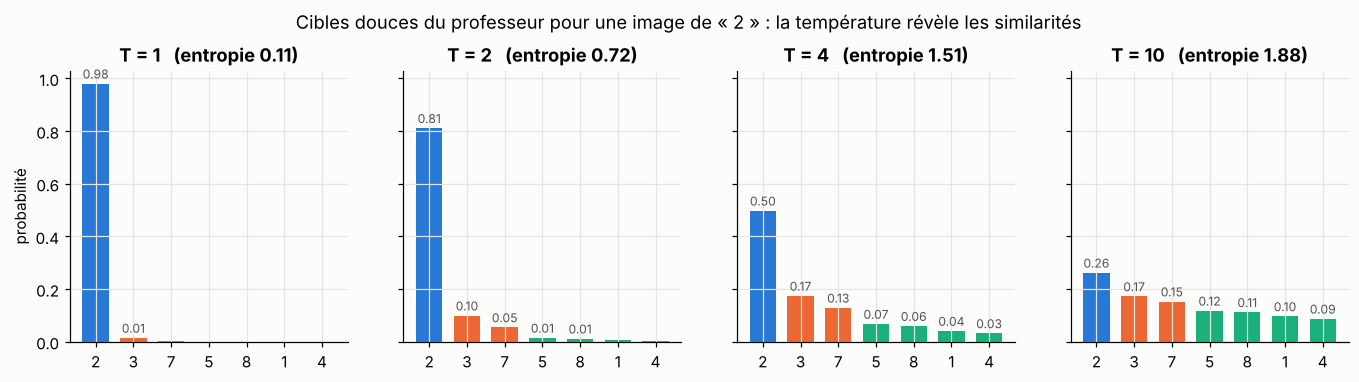

In [2]:
logits_teacher = np.array([9.0, 4.8, 3.6, 1.0, 0.5, -1.0, -2.0])     # class 0 is correct; 1 and 2 are "similar"
classes = ["2", "3", "7", "5", "8", "1", "4"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, T in zip(axes, [1, 2, 4, 10]):
    p = softmax(logits_teacher, T)
    ax.bar(classes, p, color=[PALETTE[0]] + [PALETTE[1]] * 2 + [PALETTE[2]] * 4, width=0.7)
    ax.set_title(f"T = {T}   (entropie {-(p * np.log(p)).sum():.2f})")
    for i, v in enumerate(p):
        if v > 0.01:
            ax.text(i, v + 0.02, f"{v:.2f}", ha="center", fontsize=8, color="#52514e")
axes[0].set_ylabel("probabilité")
plt.suptitle("Cibles douces du professeur pour une image de « 2 » : la température révèle les similarités", y=1.05)
plt.show()

## 3. La perte de distillation

### 📐 La perte de Hinton

Avec $z^s$ et $z^t$ les logits de l'élève et du professeur, $p^{s,T}$ et $p^{t,T}$ leurs softmax à température $T$, et $y$ l'étiquette :
$$
\boxed{\ \mathcal L = \alpha\,\underbrace{\mathrm{CE}\big(y,\ p^{s,1}\big)}_{\text{étiquettes dures}} + (1-\alpha)\,T^2\,\underbrace{\mathrm{KL}\big(p^{t,T}\,\big\|\,p^{s,T}\big)}_{\text{imitation du professeur}}\ }
$$
(Minimiser la KL ou l'entropie croisée $-\sum_i p_i^{t,T}\log p_i^{s,T}$ revient au même : elles diffèrent de l'entropie du professeur, constante pour l'élève.)

### 📐 Le gradient, et d'où vient le $T^2$

Par rapport aux logits de l'élève, le terme de distillation (avant le facteur $T^2$) donne, comme toute softmax + entropie croisée mais avec la température :
$$
\frac{\partial\,\mathrm{KL}(p^{t,T}\|p^{s,T})}{\partial z_i^s} = \frac{1}{T}\big(p_i^{s,T} - p_i^{t,T}\big)
$$
Quand $T$ grandit, $p^{s,T}$ et $p^{t,T}$ se rapprochent de l'uniforme et leur différence est elle-même en $O(1/T)$ : le gradient est en $O(1/T^2)$. Le facteur $T^2$ **compense** exactement cette atténuation, pour que la contribution des cibles douces garde le même ordre de grandeur quelle que soit $T$ (et qu'on puisse changer $T$ sans réajuster $\alpha$).

### 📐 La limite haute température : apparier les logits

Développons $\exp(z/T)\approx 1 + z/T$ pour $T$ grand, avec $K$ classes et des logits centrés ($\sum_i z_i = 0$) :
$$
p_i^{(T)}\approx\frac{1 + z_i/T}{K}\quad\Longrightarrow\quad
T^2\cdot\frac{1}{T}\big(p_i^{s,T} - p_i^{t,T}\big)\ \approx\ \frac{1}{K}\big(z_i^s - z_i^t\big)
$$
C'est le gradient de $\frac{1}{2K}\lVert z^s - z^t\rVert^2$ : **à haute température, la distillation revient à apparier les logits** par moindres carrés (la méthode de Buciluă et al. et de Ba & Caruana). Vérifions numériquement les deux formules :

gradient check, max |analytic - numeric| = 9.409629672663122e-11


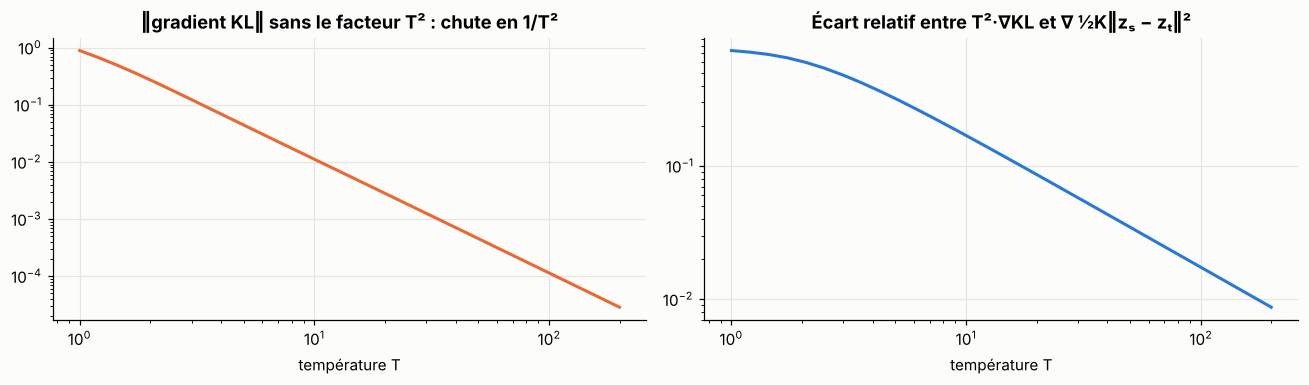

In [3]:
K_cls = 7
zs = rng.normal(size=K_cls); zt = rng.normal(size=K_cls) * 3
zs -= zs.mean(); zt -= zt.mean()                         # centered logits

def kd_loss(zs, zt, T):
    pt, ps = softmax(zt, T), softmax(zs, T)
    return (pt * (np.log(pt) - np.log(ps))).sum()        # KL(p_t || p_s)

T = 3.0
analytic = (softmax(zs, T) - softmax(zt, T)) / T
eps = 1e-6
numeric = np.array([(kd_loss(zs + eps * np.eye(K_cls)[i], zt, T) - kd_loss(zs - eps * np.eye(K_cls)[i], zt, T)) / (2 * eps) for i in range(K_cls)])
print("gradient check, max |analytic - numeric| =", np.abs(analytic - numeric).max())

Ts = np.logspace(0, 2.3, 30)
gap = [np.linalg.norm(T_ * (softmax(zs, T_) - softmax(zt, T_)) - (zs - zt) / K_cls) / np.linalg.norm((zs - zt) / K_cls) for T_ in Ts]
raw = [np.linalg.norm((softmax(zs, T_) - softmax(zt, T_)) / T_) for T_ in Ts]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].loglog(Ts, raw, color=PALETTE[1]); axes[0].set_title("‖gradient KL‖ sans le facteur T² : chute en 1/T²")
axes[0].set_xlabel("température T")
axes[1].loglog(Ts, gap, color=PALETTE[0]); axes[1].set_title("Écart relatif entre T²·∇KL et ∇ ½K‖zₛ − zₜ‖²")
axes[1].set_xlabel("température T")
plt.tight_layout(); plt.show()

## 4. Expérience 1 : quand la distillation aide (et quand elle n'aide pas)

On reprend le MLP NumPy du module 0 sur des **spirales à 5 classes** :
- le **professeur** : un MLP 2 → 256 → 256 → 5, entraîné sur 3 000 exemples annotés ;
- l'**élève** : un MLP 2 → 32 → 5 (environ 260 fois moins de paramètres), dans un régime **pauvre en annotations** : 200 exemples annotés, plus éventuellement un **jeu de transfert** de 3 000 exemples **non annotés**.

On compare plusieurs façons d'entraîner l'élève.

In [4]:
def spirals(n_per, K=5, noise=0.25, seed=0):
    r = np.random.default_rng(seed); X, y = [], []
    for k in range(K):
        t = np.linspace(0.05, 1, n_per)
        a = np.linspace(k * 2 * np.pi / K, k * 2 * np.pi / K + 3.5, n_per) + r.normal(0, noise, n_per)
        X.append(np.c_[t * np.sin(a), t * np.cos(a)]); y.append(np.full(n_per, k))
    X, y = np.vstack(X), np.concatenate(y); p = r.permutation(len(y))
    return X[p], y[p]


class MLP:
    def __init__(self, sizes, seed=0):
        r = np.random.default_rng(seed)
        self.W = [r.normal(0, np.sqrt(2 / a), (a, b)) for a, b in zip(sizes[:-1], sizes[1:])]
        self.b = [np.zeros(b) for b in sizes[1:]]
    def forward(self, X):
        self.cache = [X]; A = X
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            Z = A @ W + b
            A = np.maximum(0, Z) if i < len(self.W) - 1 else Z
            self.cache.append(A)
        return A
    def backward(self, dZ):
        gW, gb = [None] * len(self.W), [None] * len(self.W)
        for i in reversed(range(len(self.W))):
            gW[i] = self.cache[i].T @ dZ; gb[i] = dZ.sum(0)
            if i > 0:
                dZ = (dZ @ self.W[i].T) * (self.cache[i] > 0)
        return gW + gb
    def n_params(self):
        return sum(w.size for w in self.W) + sum(b.size for b in self.b)


class Adam:
    def __init__(self, params, lr):
        self.p, self.lr = params, lr
        self.m = [np.zeros_like(p) for p in params]; self.v = [np.zeros_like(p) for p in params]; self.t = 0
    def step(self, grads):
        self.t += 1
        for p, g, m, v in zip(self.p, grads, self.m, self.v):
            m *= 0.9; m += 0.1 * g; v *= 0.999; v += 0.001 * g * g
            p -= self.lr * (m / (1 - 0.9 ** self.t)) / (np.sqrt(v / (1 - 0.999 ** self.t)) + 1e-8)


def train(net, X, y=None, soft=None, T=1.0, alpha=1.0, epochs=200, bs=64, lr=5e-3, seed=0):
    """alpha weights the hard-label CE; (1 - alpha) * T^2 * KL weights the soft targets (if given)."""
    r = np.random.default_rng(seed); opt = Adam(net.W + net.b, lr)
    for ep in range(epochs):
        perm = r.permutation(len(X))
        for k in range(0, len(X), bs):
            i = perm[k:k + bs]; Z = net.forward(X[i]); B = len(i); dZ = np.zeros_like(Z)
            if y is not None and alpha > 0:
                P = softmax(Z); P[np.arange(B), y[i]] -= 1
                dZ += alpha * P / B
            if soft is not None:
                w = (1 - alpha) if y is not None else 1.0
                dZ += w * T ** 2 * (softmax(Z, T) - soft[i]) / T / B     # T^2 * (1/T) (p_s - p_t)
            opt.step(net.backward(dZ))
    return net

acc = lambda net, X, y: float((net.forward(X).argmax(1) == y).mean())
K = 5
X_test, y_test = spirals(1000, K, seed=99)
X_teacher, y_teacher = spirals(600, K, seed=1)             # 3000 labeled examples for the teacher
X_lab, y_lab = spirals(40, K, seed=2)                      # 200 labeled examples for the student
X_transfer, y_transfer_hidden = spirals(600, K, seed=7)    # 3000 UNLABELED examples (labels kept only for analysis)

teacher = train(MLP([2, 256, 256, K], seed=1), X_teacher, y_teacher, epochs=200)
print(f"teacher: {MLP([2, 256, 256, K]).n_params():,} params | test acc {acc(teacher, X_test, y_test):.3f}")
print(f"student: {MLP([2, 32, K]).n_params():,} params")

teacher: 67,845 params | test acc 0.982
student: 261 params


élève, 200 étiquettes                      0.950
élève, 200 ex. + KD (T=1)                  0.952
élève, 200 ex. + KD (T=4)                  0.917
élève, 3000 pseudo-étiquettes dures        0.980
élève, 3000 cibles douces (T=1)            0.981
élève, 3000 cibles douces (T=4)            0.969
élève, 3000 vraies étiquettes (plafond)    0.980
professeur                                 0.982


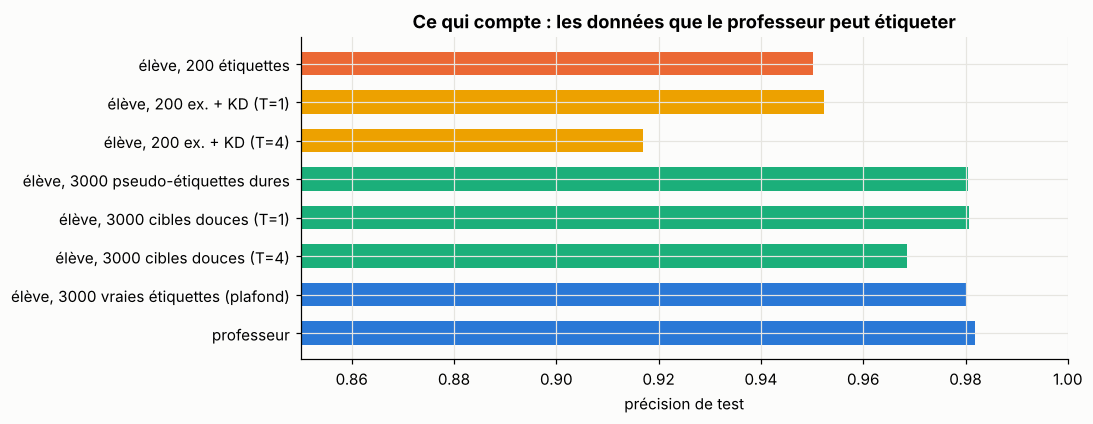

In [5]:
results = {}
results["élève, 200 étiquettes"] = acc(train(MLP([2, 32, K], 3), X_lab, y_lab, epochs=400), X_test, y_test)
for T_ in [1, 4]:
    soft = softmax(teacher.forward(X_lab), T_)
    results[f"élève, 200 ex. + KD (T={T_})"] = acc(train(MLP([2, 32, K], 3), X_lab, y_lab, soft=soft, T=T_, alpha=0.1, epochs=400), X_test, y_test)
pseudo = teacher.forward(X_transfer).argmax(1)
results["élève, 3000 pseudo-étiquettes dures"] = acc(train(MLP([2, 32, K], 3), X_transfer, pseudo, epochs=150), X_test, y_test)
for T_ in [1, 4]:
    soft = softmax(teacher.forward(X_transfer), T_)
    results[f"élève, 3000 cibles douces (T={T_})"] = acc(train(MLP([2, 32, K], 3), X_transfer, soft=soft, T=T_, epochs=150), X_test, y_test)
results["élève, 3000 vraies étiquettes (plafond)"] = acc(train(MLP([2, 32, K], 3), X_teacher, y_teacher, epochs=200), X_test, y_test)
results["professeur"] = acc(teacher, X_test, y_test)
for k, v in results.items():
    print(f"{k:42s} {v:.3f}")

fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(results)
cols = [PALETTE[1]] + [PALETTE[3]] * 2 + [PALETTE[2]] * 3 + [PALETTE[0]] * 2
ax.barh(names[::-1], [results[k] for k in names][::-1], color=cols[::-1], height=0.6)
ax.set_xlim(0.85, 1.0); ax.set_xlabel("précision de test"); ax.set_title("Ce qui compte : les données que le professeur peut étiqueter")
plt.show()

**Lecture critique** :
- **Sur les mêmes 200 exemples**, la distillation n'apporte rien ici, et une température élevée **dégrade** même un peu. Ce n'est pas une anomalie : quand l'élève a assez de capacité et que les classes sont bien séparées, les étiquettes dures contiennent presque toute l'information utile. Les gains de la « distillation sur les mêmes données » rapportés dans la littérature sont souvent modestes et dépendants du réglage.
- **Le vrai levier est le jeu de transfert** : avec 3 000 exemples non annotés étiquetés par le professeur, l'élève atteint presque le professeur, et presque son propre plafond avec les vraies étiquettes. La distillation sert d'abord à **exploiter des données non annotées**.
- Ici, pseudo-étiquettes dures et cibles douces font jeu égal : le problème est simple. L'avantage des cibles douces apparaît quand la **structure entre classes** compte : c'est l'expérience suivante.

## 5. Expérience 2 : la connaissance sombre

Reproduction miniature d'une expérience de Hinton et al. : on **retire du jeu de transfert tous les exemples d'une classe** (la classe 2). L'élève ne voit **jamais** un exemple de cette classe. Avec des pseudo-étiquettes dures, il ne peut presque pas la prédire. Avec des cibles douces, il reçoit malgré tout, sur les exemples des **autres** classes situés près de la frontière, la probabilité que le professeur accorde à la classe 2, et peut en reconstruire une partie.

fraction of transfer examples whose hard pseudo-label is class 2: 0.003
recall on the NEVER-SEEN class 2 with pseudo-étiquettes dures : 0.224
recall on the NEVER-SEEN class 2 with cibles douces T=1       : 0.326
recall on the NEVER-SEEN class 2 with cibles douces T=4       : 0.554
recall on the NEVER-SEEN class 2 with cibles douces T=8       : 0.368


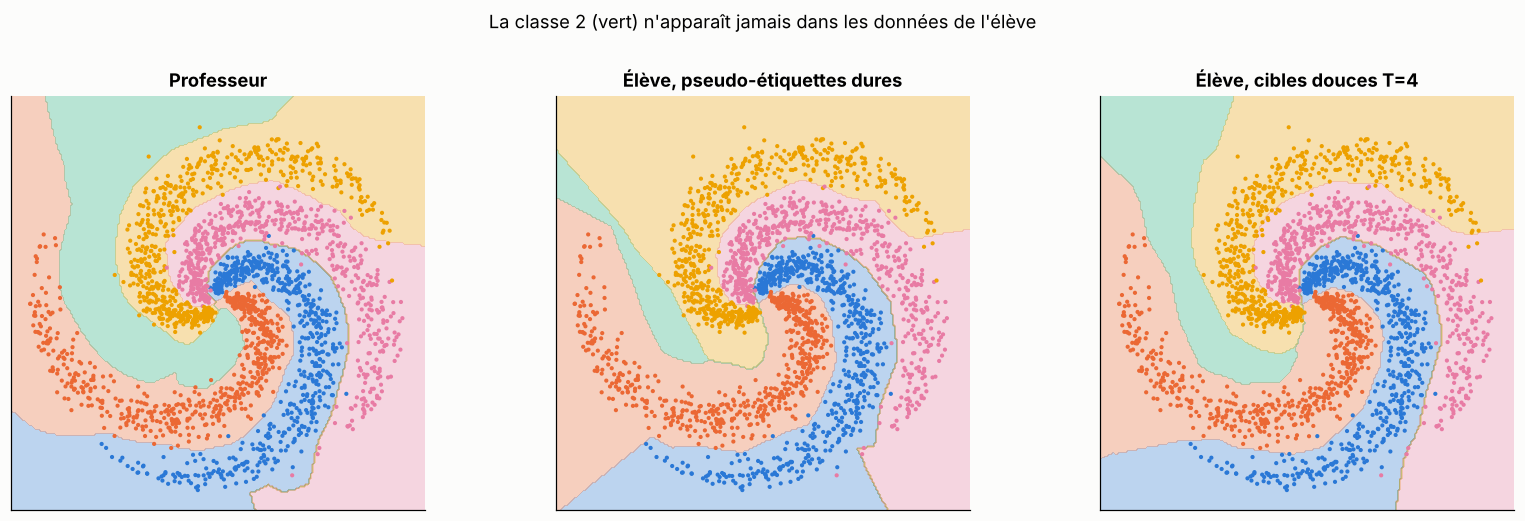

In [6]:
hidden_class = 2
keep = y_transfer_hidden != hidden_class
mask_test = y_test == hidden_class
out = {}
pl = teacher.forward(X_transfer[keep]).argmax(1)
st_hard = train(MLP([2, 32, K], 3), X_transfer[keep], pl, epochs=150)
out["pseudo-étiquettes dures"] = (st_hard.forward(X_test).argmax(1)[mask_test] == hidden_class).mean()
students = {}
for T_ in [1, 4, 8]:
    st = train(MLP([2, 32, K], 3), X_transfer[keep], soft=softmax(teacher.forward(X_transfer[keep]), T_), T=T_, epochs=150)
    students[T_] = st
    out[f"cibles douces T={T_}"] = (st.forward(X_test).argmax(1)[mask_test] == hidden_class).mean()
print(f"fraction of transfer examples whose hard pseudo-label is class {hidden_class}: {(pl == hidden_class).mean():.3f}")
for k, v in out.items():
    print(f"recall on the NEVER-SEEN class {hidden_class} with {k:24s}: {v:.3f}")

cmap5 = ListedColormap(PALETTE[:5])
xx, yy = np.meshgrid(np.linspace(-1.1, 1.1, 220), np.linspace(-1.1, 1.1, 220))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, net) in zip(axes, [("Professeur", teacher), ("Élève, pseudo-étiquettes dures", st_hard),
                                   ("Élève, cibles douces T=4", students[4])]):
    ax.contourf(xx, yy, net.forward(grid).argmax(1).reshape(xx.shape), levels=np.arange(-0.5, 5), cmap=cmap5, alpha=0.3)
    ax.scatter(X_transfer[keep][:, 0], X_transfer[keep][:, 1], c=y_transfer_hidden[keep], cmap=cmap5, s=3, vmin=0, vmax=4)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_aspect("equal")
plt.suptitle(f"La classe {hidden_class} (vert) n'apparaît jamais dans les données de l'élève", y=1.02)
plt.tight_layout(); plt.show()

La région de la classe cachée réapparaît en partie chez l'élève distillé avec des cibles douces, à partir des seules probabilités « secondaires » du professeur. La température compte : trop basse, le signal secondaire est écrasé ; trop haute, il est noyé dans l'uniforme. Hinton et al. ajoutaient aussi un ajustement du biais de la classe absente pour compenser son absence totale dans les données.

> 🎯 **Leçon générale** : les cibles douces transmettent de l'information **qui n'est pas dans les étiquettes**, mais seulement si le professeur l'a apprise, et seulement là où l'élève reçoit des exemples. Un élève ne peut pas découvrir ce que le professeur ignore : **il hérite aussi de ses erreurs et de ses biais**.

## 6. Les variantes

### 6.1 Distiller les représentations internes

Les sorties ne sont qu'un petit goulot d'information. On peut aussi faire imiter à l'élève les **états cachés** et les **cartes d'attention** du professeur :
$$
\mathcal L_{\text{hidden}} = \sum_{l}\big\lVert H^s_{l}\,W_l - H^t_{g(l)}\big\rVert^2,\qquad
\mathcal L_{\text{attn}} = \sum_{l}\frac{1}{h}\sum_{a=1}^{h}\big\lVert A^s_{l,a} - A^t_{g(l),a}\big\rVert^2
$$
où $g(l)$ associe une couche de l'élève à une couche du professeur (par exemple une sur trois) et $W_l$ est une projection apprise si les dimensions diffèrent (FitNets, Romero et al., 2015 ; **TinyBERT**). **DistilBERT** combine trois pertes : MLM (étiquettes), KD sur les sorties MLM, et une perte **cosinus** entre états cachés ; il initialise l'élève en **prenant une couche sur deux** du professeur.

### 6.2 Distillation de séquences (génération)

Pour un modèle seq2seq ou un LM, distiller token par token (KL à chaque position) est possible, mais Kim & Rush (2016) montrent qu'il est souvent plus efficace de faire **générer** au professeur (beam search) et d'entraîner l'élève sur ces **séquences** comme si c'étaient des données (*sequence-level KD*). C'est le principe de nombreux petits LLM entraînés sur des données synthétiques produites par de grands modèles.

### 6.3 Auto-distillation

Le professeur et l'élève ont **la même architecture** : « Born-Again Networks » (Furlanello et al., 2018) montrent que l'élève dépasse souvent le professeur. La distillation agit alors comme une **régularisation** (proche du *label smoothing*, mais avec un lissage appris et propre à chaque exemple) et améliore souvent la **calibration** (module 8).

### 6.4 Pseudo-étiquetage et auto-entraînement

Le professeur étiquette des données non annotées, on garde les prédictions confiantes, on entraîne l'élève, et l'élève devient le nouveau professeur (*self-training*, *Noisy Student*, Xie et al., 2020 : l'élève reçoit du **bruit** — dropout, augmentations — que le professeur n'avait pas, ce qui l'oblige à généraliser au lieu de recopier).

### 6.5 Distiller un outil existant

Un cas très fréquent en bioinformatique : le « professeur » est un **outil d'annotation** (alignement à des références, règles expertes), lent ou dépendant de bases de référence, et on entraîne un réseau à reproduire ses sorties à grande échelle. C'est de la distillation au sens large, avec trois points de vigilance :
- l'élève apprend les **erreurs systématiques** de l'outil ; il faut un jeu d'évaluation **expertisé indépendamment** pour savoir si l'élève fait mieux, aussi bien ou moins bien que son professeur ;
- un désaccord élève / outil n'est pas forcément une erreur de l'élève : ces désaccords sont à **analyser au cas par cas** et peuvent révéler des cas limites ;
- on peut récupérer une forme de **cible douce** même d'un outil discret (scores d'alignement, plusieurs hypothèses classées, probabilités par vote), ce qui transmet son incertitude à l'élève.

## 7. Distiller un Transformer avec PyTorch / Hugging Face

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForSequenceClassification, AutoModelForTokenClassification, AutoTokenizer


def kd_loss(student_logits, teacher_logits, labels=None, T=2.0, alpha=0.5, ignore_index=-100):
    """Hinton loss for (B, C) or (B, L, C) logits. Positions with labels == ignore_index are excluded."""
    C = student_logits.size(-1)
    s, t = student_logits.reshape(-1, C), teacher_logits.reshape(-1, C)
    if labels is not None:
        valid = labels.reshape(-1) != ignore_index
        s, t, y = s[valid], t[valid], labels.reshape(-1)[valid]
    # F.kl_div expects LOG-probabilities for the input and probabilities for the target: KL(target || input)
    soft = F.kl_div(F.log_softmax(s / T, dim=-1), F.softmax(t / T, dim=-1), reduction="batchmean") * T ** 2
    if labels is None:
        return soft
    return alpha * F.cross_entropy(s, y) + (1 - alpha) * soft


# Sanity check against the formula
s_log, t_log = torch.randn(4, 5), torch.randn(4, 5)
manual = (F.softmax(t_log / 2, -1) * (F.log_softmax(t_log / 2, -1) - F.log_softmax(s_log / 2, -1))).sum(-1).mean() * 4
print(torch.allclose(kd_loss(s_log, t_log, T=2.0), manual))

> ⚠️ **Les trois pièges classiques de `F.kl_div`** : (1) le premier argument doit être des **log**-probabilités, le second des probabilités (sinon la perte est silencieusement fausse) ; (2) `reduction="mean"` moyenne aussi sur les classes, il faut `"batchmean"` pour la vraie KL moyenne par exemple ; (3) ne pas oublier `T ** 2`.

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
teacher_name = "camembert-base"                                   # in practice: a teacher ALREADY fine-tuned on the task
student_name = "distilbert-base-multilingual-cased"               # any smaller encoder; tokenizers may differ!

teacher_tok, student_tok = AutoTokenizer.from_pretrained(teacher_name), AutoTokenizer.from_pretrained(student_name)
teacher_clf = AutoModelForSequenceClassification.from_pretrained(teacher_name, num_labels=2).to(device).eval()
student_clf = AutoModelForSequenceClassification.from_pretrained(student_name, num_labels=2).to(device)
opt = torch.optim.AdamW(student_clf.parameters(), lr=5e-5, weight_decay=0.01)

texts = ["Un film magnifique.", "Je me suis ennuyé.", "Pas mal du tout.", "Une catastrophe."]   # transfer set (unlabeled is fine)
labels = torch.tensor([1, 0, 1, 0], device=device)                                            # optional

for epoch in range(3):
    with torch.no_grad():                                         # the teacher is frozen: no graph, eval mode
        t_logits = teacher_clf(**teacher_tok(texts, padding=True, return_tensors="pt").to(device)).logits
    s_logits = student_clf(**student_tok(texts, padding=True, return_tensors="pt").to(device)).logits
    loss = kd_loss(s_logits, t_logits, labels, T=2.0, alpha=0.5)
    opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {epoch} | distillation loss {loss.item():.4f}")

**Distiller un étiqueteur de tokens** (NER, régions) quand professeur et élève ont des **tokenizers différents** : les logits ne sont pas alignés token à token. Solution : ramener les deux au niveau des **mots** (ou des résidus pour des protéines, où le problème disparaît si les deux modèles tokenisent par résidu), en prenant le logit du premier sous-mot de chaque mot (comme au module 10), puis appliquer `kd_loss` au niveau des mots.

In [ ]:
@torch.no_grad()
def word_level_logits(model, tok, words_batch):
    enc = tok(words_batch, is_split_into_words=True, padding=True, truncation=True, return_tensors="pt").to(device)
    logits = model(**enc).logits                                   # (B, T_sub, C)
    W = max(len(w) for w in words_batch)
    out = torch.zeros(len(words_batch), W, logits.size(-1), device=device)
    mask = torch.zeros(len(words_batch), W, dtype=torch.bool, device=device)
    for b in range(len(words_batch)):
        seen = set()
        for pos, wid in enumerate(enc.word_ids(b)):
            if wid is not None and wid not in seen:
                seen.add(wid); out[b, wid] = logits[b, pos]; mask[b, wid] = True
    return out, mask
# For the STUDENT, do the same gather but WITHOUT torch.no_grad(), then:
# loss = kd_loss(student_word_logits[mask], teacher_word_logits[mask], T=2.0)

**Check-list d'une distillation sérieuse** :
- [ ] professeur **affiné et évalué** d'abord (un mauvais professeur fait un mauvais élève) ;
- [ ] baseline : le même élève entraîné **sans** distillation, avec le même budget de réglage ;
- [ ] balayage de $T\in\{1, 2, 4, 8\}$ et $\alpha$ sur la validation ;
- [ ] mesurer ce qui motive la distillation : latence, mémoire, débit (sur le matériel cible), pas seulement la précision ;
- [ ] comparer **élève vs professeur sur les exemples où le professeur se trompe** : l'élève les reproduit-il ?

## 8. Récapitulatif

| Notion | À retenir |
|---|---|
| Objectif | un élève petit imite un professeur grand (ou un système non différentiable) |
| Cibles douces | softmax à température $T$ ; révèlent la similarité entre classes (connaissance sombre) |
| Perte | $\alpha\,\mathrm{CE}(y, p^s) + (1-\alpha)T^2\,\mathrm{KL}(p^{t,T}\|p^{s,T})$ |
| Gradient | $\frac1T(p^{s,T}-p^{t,T})$ ; $T^2$ compense l'atténuation en $1/T^2$ |
| Haute température | équivaut à apparier les logits centrés (MSE) |
| Ce qui aide vraiment | un **jeu de transfert** non annoté étiqueté par le professeur |
| Variantes | états cachés et attention (TinyBERT), DistilBERT, séquences (Kim & Rush), auto-distillation, Noisy Student |
| Limites | l'élève hérite des erreurs du professeur ; évaluer sur des étiquettes indépendantes |
| PyTorch | `F.kl_div(log_softmax(s/T), softmax(t/T), reduction="batchmean") * T**2` |

### 🏋️ Exercices

1. **Élève minuscule.** Refais l'expérience 1 avec un élève 2 → 8 → 5. La distillation sur les mêmes 200 exemples aide-t-elle davantage quand l'élève est **à court de capacité** ?
2. **Étiquettes bruitées.** Corromps 30 % des 3 000 étiquettes du professeur. Entraîne-le, puis distille un élève sur un jeu de transfert. L'élève fait-il mieux que le professeur ? (Indice : auto-distillation, régularisation.)
3. **Calibration.** Compare l'ECE (module 8) d'un élève entraîné sur étiquettes dures et d'un élève distillé. Laquelle des deux est la mieux calibrée ?
4. **Appariement de logits.** Remplace la perte KL par $\frac{1}{2K}\lVert z^s - z^t\rVert^2$ sur des logits centrés. Compare aux cibles douces à $T = 1, 4, 20$.
5. **Ton projet.** Si un outil existant fournit tes étiquettes d'entraînement, décris comment tu mesurerais (a) l'accord élève / outil, (b) la justesse de chacun sur un jeu expertisé, (c) les cas où l'élève corrige l'outil.

<details><summary>Indications</summary>

1. Les gains de la distillation sont classiquement plus nets quand l'écart de capacité est réel : l'élève ne peut pas représenter la frontière exacte et bénéficie d'une cible plus « lisse ».
2. Le professeur sur-apprend une partie du bruit ; ses sorties douces sur les données de transfert lissent ce bruit, et l'élève peut le dépasser.
4. À haute température, KL et MSE sur logits centrés convergent (section 3) ; à basse température, la KL se concentre sur la classe dominante.
</details>

**➡️ Module suivant : l'apprentissage multi-tâche en profondeur** (partage dur et souple, conflits de gradients, PCGrad, GradNorm, DWA, échantillonnage des tâches, mesure du transfert négatif).